In [27]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data" / "raw"

STATIONS_FILE = DATA_DIR / "bike_stations_with_attributes.geojson"
WEATHER_FILE = DATA_DIR / "weather_data.csv"

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("Environment ready!")
print("Data directory:", DATA_DIR.resolve())

Environment ready!
Data directory: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\raw


In [28]:
stations = gpd.read_file(STATIONS_FILE)

In [15]:
from pathlib import Path
import sqlite3
import pandas as pd

# Find project root (parent of notebooks folder)
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Define database location
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
DB_FILE = PROCESSED_DIR / "bike_hourly.sqlite"

# Check that database exists
if not DB_FILE.exists():
    raise FileNotFoundError(f"Database not found: {DB_FILE}")

print("Project directory:", PROJECT_DIR)
print("Database file:", DB_FILE)
print("Database size (MB):", round(DB_FILE.stat().st_size / (1024**2), 2))

# Connect to SQLite
conn = sqlite3.connect(DB_FILE)

print("SQLite connection successful!")

Project directory: C:\Users\piotr\PycharmProjects\warsaw_bike_demand
Database file: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\processed\bike_hourly.sqlite
Database size (MB): 200.12
SQLite connection successful!


In [16]:
# validate sql db
import pandas as pd
import sqlite3

conn = sqlite3.connect(DB_FILE)

summary = pd.read_sql_query("""
SELECT
    COUNT(*) AS hourly_station_records,
    COUNT(DISTINCT station_id) AS unique_stations,
    COUNT(DISTINCT hour) AS unique_hours,
    MIN(hour) AS first_hour,
    MAX(hour) AS last_hour,
    ROUND(AVG(observations), 2) AS avg_snapshots_per_station_hour,
    MIN(observations) AS min_snapshots,
    MAX(observations) AS max_snapshots
FROM hourly_station
""", conn)

display(summary)

,hourly_station_records,unique_stations,unique_hours,first_hour,last_hour,avg_snapshots_per_station_hour,min_snapshots,max_snapshots
0,1595502,333,4975,2023-05-06 09:00,2023-11-29 15:00,12.0,1,12


In [17]:
integrity = conn.execute("PRAGMA integrity_check").fetchone()[0]

print("Database integrity:", integrity)
print("Database size (MB):", round(DB_FILE.stat().st_size / 1024**2, 2))

Database integrity: ok
Database size (MB): 200.12


In [18]:
hourly_df = pd.read_sql_query("""
SELECT
    hour AS timestamp,
    station_id,
    name,
    latitude,
    longitude,

    sum_available_bikes * 1.0 / observations
        AS avg_available_bikes,

    min_available_bikes,

    stockout_observations,

    stockout_observations * 1.0 / observations
        AS stockout_rate,

    sum_free_racks * 1.0 / observations
        AS avg_free_racks,

    observations

FROM hourly_station
ORDER BY timestamp, station_id
""", conn)

hourly_df["timestamp"] = pd.to_datetime(hourly_df["timestamp"])

print("Dataset shape:", hourly_df.shape)
display(hourly_df.head())

Dataset shape: (1595502, 11)


,timestamp,station_id,name,latitude,longitude,avg_available_bikes,min_available_bikes,stockout_observations,stockout_rate,avg_free_racks,observations
0,2023-05-06 09:00:00,145175382,Korkowa,52.238280,21.147235,14.083333,14.0,0,0.0,0.000000,12
1,2023-05-06 09:00:00,163208604,Paderewskiego - Czwartaków,52.271148,21.149855,5.000000,5.0,0,0.0,5.000000,12
2,2023-05-06 09:00:00,172293631,Dolina Służewiecka - Nowoursynowska,52.170340,21.041258,7.000000,7.0,0,0.0,3.000000,12
3,2023-05-06 09:00:00,172294162,Kłobucka - Jurajska,52.163700,20.992412,9.916667,9.0,0,0.0,0.083333,12
4,2023-05-06 09:00:00,172295073,Puławska - Bogatki,52.132479,21.018331,14.000000,14.0,0,0.0,0.000000,12


In [19]:
print("Average bikes available:",
      round(hourly_df["avg_available_bikes"].mean(), 2))

print("Percentage of station-hours with at least one stockout:",
      round(
          (hourly_df["stockout_observations"] > 0).mean() * 100,
          2
      ), "%")

print("Station-hour records with incomplete observations:",
      (hourly_df["observations"] < 12).sum())

Average bikes available: 8.14
Percentage of station-hours with at least one stockout: 13.3 %
Station-hour records with incomplete observations: 2032


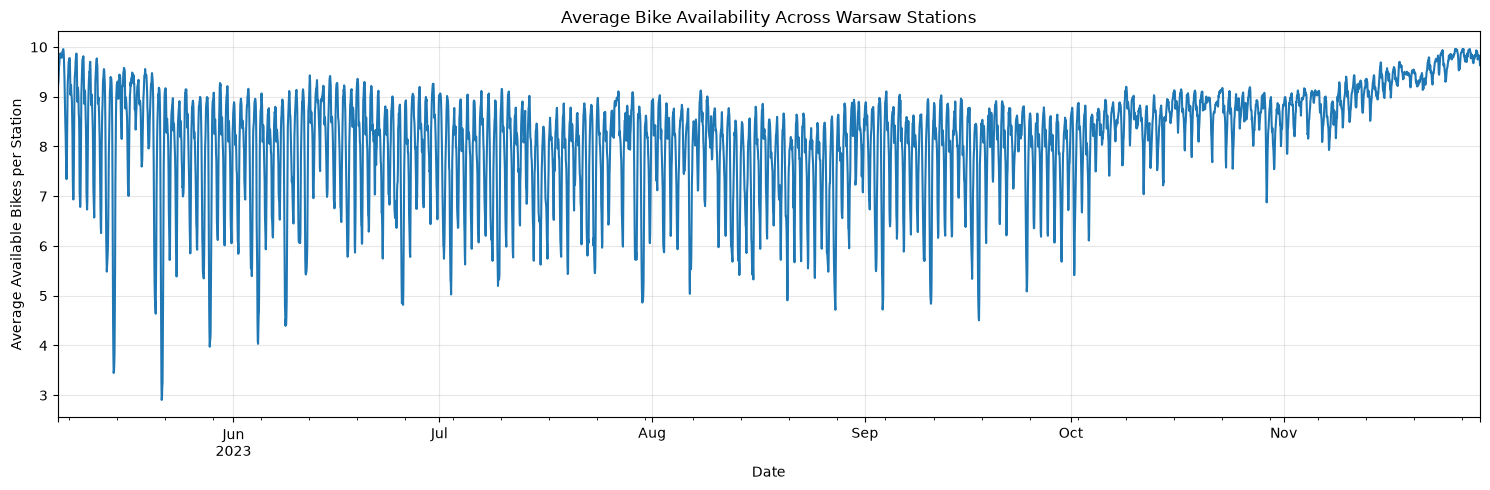

In [20]:
import matplotlib.pyplot as plt

hourly_trend = (
    hourly_df.groupby("timestamp")["avg_available_bikes"]
    .mean()
)

plt.figure(figsize=(15, 5))
hourly_trend.plot()
plt.title("Average Bike Availability Across Warsaw Stations")
plt.xlabel("Date")
plt.ylabel("Average Available Bikes per Station")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

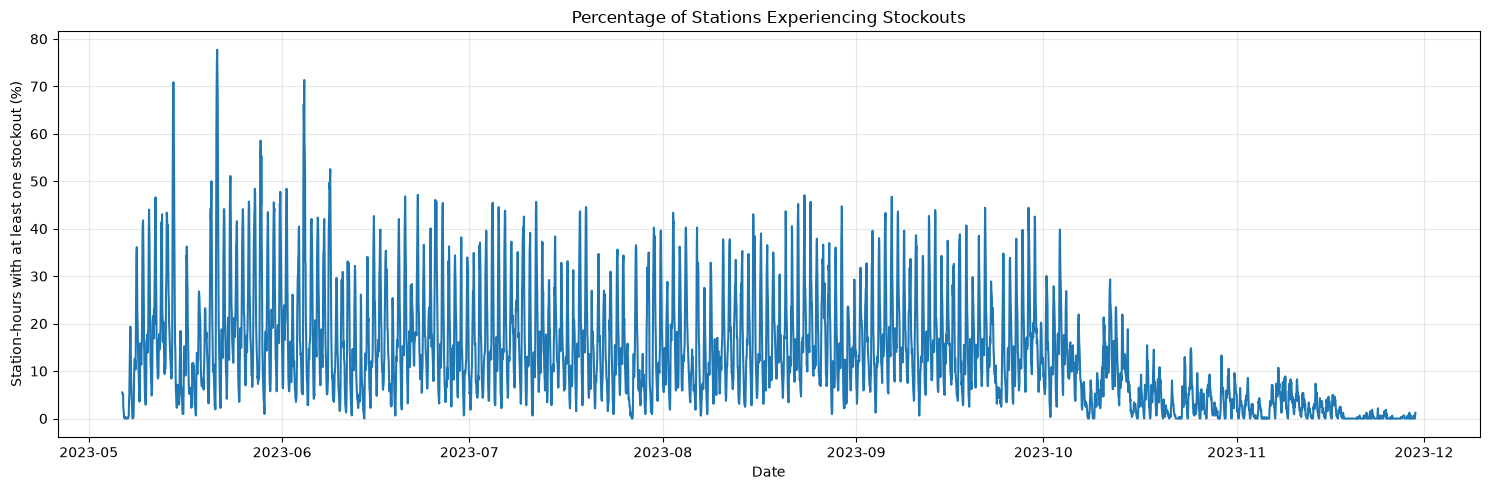

In [21]:
stockout_trend = (
    hourly_df.assign(
        stockout=(
            hourly_df["stockout_observations"] > 0
        ).astype(int)
    )
    .groupby("timestamp")["stockout"]
    .mean() * 100
)

plt.figure(figsize=(15, 5))
plt.plot(stockout_trend.index, stockout_trend.values)

plt.title("Percentage of Stations Experiencing Stockouts")
plt.xlabel("Date")
plt.ylabel("Station-hours with at least one stockout (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# How many bikes will be available at each station one hour from now? 
model_df = hourly_df.sort_values(
    ["station_id", "timestamp"]
).copy()

grouped = model_df.groupby("station_id", sort=False)

model_df["next_timestamp"] = (
    grouped["timestamp"].shift(-1)
)

model_df["target_next_hour"] = (
    grouped["avg_available_bikes"].shift(-1)
)

model_df["target_gap"] = (
    model_df["next_timestamp"] - model_df["timestamp"]
)

# Retain only consecutive hours
model_df = model_df[
    model_df["target_gap"] == pd.Timedelta(hours=1)
].copy()

# Time features
model_df["hour"] = model_df["timestamp"].dt.hour
model_df["day_of_week"] = model_df["timestamp"].dt.day_of_week
model_df["month"] = model_df["timestamp"].dt.month
model_df["is_weekend"] = (
    model_df["day_of_week"] >= 5
).astype(int)

# Cyclical encoding of time
import numpy as np

model_df["hour_sin"] = np.sin(
    2 * np.pi * model_df["hour"] / 24
)
model_df["hour_cos"] = np.cos(
    2 * np.pi * model_df["hour"] / 24
)

model_df["weekday_sin"] = np.sin(
    2 * np.pi * model_df["day_of_week"] / 7
)
model_df["weekday_cos"] = np.cos(
    2 * np.pi * model_df["day_of_week"] / 7
)

print("Training dataset shape:", model_df.shape)
print("First timestamp:", model_df["timestamp"].min())
print("Last timestamp:", model_df["timestamp"].max())

display(model_df.head())

Training dataset shape: (1595121, 22)
First timestamp: 2023-05-06 09:00:00
Last timestamp: 2023-11-29 14:00:00


,timestamp,station_id,name,latitude,longitude,avg_available_bikes,min_available_bikes,stockout_observations,stockout_rate,avg_free_racks,...,target_next_hour,target_gap,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,weekday_sin,weekday_cos
98363,2023-05-19 15:00:00,14083304,Procter&Gamble,52.260904,21.072881,9.090909,0.0,1,0.090909,0.0,...,10.000000,0 days 01:00:00,15,4,5,0,-0.707107,-7.071068e-01,-0.433884,-0.900969
98676,2023-05-19 16:00:00,14083304,Procter&Gamble,52.260904,21.072881,10.000000,10.0,0,0.000000,0.0,...,10.000000,0 days 01:00:00,16,4,5,0,-0.866025,-5.000000e-01,-0.433884,-0.900969
98990,2023-05-19 17:00:00,14083304,Procter&Gamble,52.260904,21.072881,10.000000,10.0,0,0.000000,0.0,...,10.000000,0 days 01:00:00,17,4,5,0,-0.965926,-2.588190e-01,-0.433884,-0.900969
99304,2023-05-19 18:00:00,14083304,Procter&Gamble,52.260904,21.072881,10.000000,10.0,0,0.000000,0.0,...,10.166667,0 days 01:00:00,18,4,5,0,-1.000000,-1.836970e-16,-0.433884,-0.900969
99618,2023-05-19 19:00:00,14083304,Procter&Gamble,52.260904,21.072881,10.166667,10.0,0,0.000000,0.0,...,11.000000,0 days 01:00:00,19,4,5,0,-0.965926,2.588190e-01,-0.433884,-0.900969


In [23]:

import pandas as pd
import numpy as np

model_df = hourly_df.sort_values(
    ["station_id", "timestamp"]
).copy()

grouped = model_df.groupby("station_id", sort=False)

model_df["next_timestamp"] = grouped["timestamp"].shift(-1)
model_df["target_next_hour"] = grouped["avg_available_bikes"].shift(-1)
model_df["next_observations"] = grouped["observations"].shift(-1)

# Keep only consecutive hours with complete observations
model_df = model_df[
    (model_df["next_timestamp"] == model_df["timestamp"] + pd.Timedelta(hours=1))
    & (model_df["observations"] == 12)
    & (model_df["next_observations"] == 12)
].copy()

# Time features
model_df["hour"] = model_df["timestamp"].dt.hour
model_df["day_of_week"] = model_df["timestamp"].dt.day_of_week
model_df["month"] = model_df["timestamp"].dt.month
model_df["is_weekend"] = (model_df["day_of_week"] >= 5).astype(int)

model_df["hour_sin"] = np.sin(2 * np.pi * model_df["hour"] / 24)
model_df["hour_cos"] = np.cos(2 * np.pi * model_df["hour"] / 24)
model_df["weekday_sin"] = np.sin(2 * np.pi * model_df["day_of_week"] / 7)
model_df["weekday_cos"] = np.cos(2 * np.pi * model_df["day_of_week"] / 7)

print("Clean modelling dataset:", model_df.shape)
print("First timestamp:", model_df["timestamp"].min())
print("Last timestamp:", model_df["timestamp"].max())
print("Complete target hours:", model_df["next_observations"].eq(12).all())


Clean modelling dataset: (1591164, 22)
First timestamp: 2023-05-06 09:00:00
Last timestamp: 2023-11-29 14:00:00
Complete target hours: True


In [24]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import numpy as np

# Chronological split
unique_times = np.sort(model_df["timestamp"].unique())
split_time = unique_times[int(len(unique_times) * 0.8)]

train_df = model_df[model_df["timestamp"] < split_time].copy()
test_df = model_df[model_df["timestamp"] >= split_time].copy()

features = [
    "avg_available_bikes",
    "min_available_bikes",
    "stockout_rate",
    "avg_free_racks",
    "observations",
    "latitude",
    "longitude",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "weekday_sin",
    "weekday_cos"
]

target = "target_next_hour"

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Test begins:", split_time)

# Baseline: next hour equals current hour
baseline_predictions = X_test["avg_available_bikes"]

# XGBoost model
model = XGBRegressor(
    n_estimators=200,
    max_depth=7,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

def evaluate_model(name, actual, predicted):
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(actual, predicted), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 3))
    print("R²:", round(r2_score(actual, predicted), 3))

evaluate_model("Persistence baseline", y_test, baseline_predictions)
evaluate_model("XGBoost", y_test, predictions)


Training rows: 1267617
Testing rows: 323547
Test begins: 2023-10-19T04:00:00.000000

Persistence baseline
MAE: 0.798
RMSE: 1.521
R²: 0.876

XGBoost
MAE: 0.851
RMSE: 1.421
R²: 0.892


In [25]:
# Here's what that means:
# - MAE: The baseline's average absolute error is about 0.80 bikes, compared with 0.85 for XGBoost. So the baseline makes smaller errors on a typical prediction.
# - RMSE: XGBoost performs better here. Squared errors penalize large mistakes more heavily, so this suggests it reduces some of the larger forecasting errors.
# - R²: XGBoost explains 89.2% of the variation in the test target, versus 87.6% for the baseline.
# let's inspect which features it relies on and whether it is particularly good at predicting certain stations or availability levels 

# Feature importance
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("Top features:")
display(importance.head(10).to_frame("importance"))

# Compare absolute errors
results = test_df[
    ["timestamp", "station_id", "avg_available_bikes", "target_next_hour"]
].copy()

results["baseline_prediction"] = baseline_predictions
results["xgboost_prediction"] = predictions

results["baseline_error"] = (
    results["target_next_hour"] - results["baseline_prediction"]
).abs()

results["xgboost_error"] = (
    results["target_next_hour"] - results["xgboost_prediction"]
).abs()

print("Mean absolute error by actual availability:")
results["availability_group"] = pd.cut(
    results["target_next_hour"],
    bins=[-0.01, 2, 5, 10, 20, float("inf")],
    labels=["0–2", "2–5", "5–10", "10–20", "20+"]
)

display(
    results.groupby("availability_group", observed=False)[
        ["baseline_error", "xgboost_error"]
    ].mean().round(3)
)

# Compare error distributions
display(
    results[["baseline_error", "xgboost_error"]]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(3)
)


Top features:


,importance
avg_available_bikes,0.690192
min_available_bikes,0.219434
avg_free_racks,0.031548
stockout_rate,0.015678
hour_sin,0.005604
hour_cos,0.005567
longitude,0.005420
latitude,0.004883
month,0.004692
weekday_sin,0.004478


Mean absolute error by actual availability:


,baseline_error,xgboost_error
availability_group,,
0–2,0.970,1.233
2–5,0.810,0.772
5–10,0.703,0.734
10–20,0.847,0.930
20+,2.208,2.519


,baseline_error,xgboost_error
0.50,0.417,0.478
0.75,1.000,1.088
0.90,2.000,2.027
0.95,3.000,2.876
0.99,6.250,5.511


In [29]:
# 2–5	XGBoost perfrms better for this window difference and it wins for 95th percentile and 99th percentile
# So XGBoost reduces the worst errors, even though the baseline remains better on average.
# add station characteristics as next step

# Prepare station metadata for joining
station_features = stations.drop(columns="geometry").copy()

station_features["uid"] = station_features["uid"].astype(str)

# Join station attributes to modelling dataset
model_with_metadata = model_df.merge(
    station_features,
    left_on="station_id",
    right_on="uid",
    how="left",
    validate="many_to_one"
)

metadata_columns = [
    col for col in station_features.columns
    if col not in ["uid", "lat", "lon"]
]

print("Rows:", len(model_with_metadata))
print(
    "Rows without metadata:",
    model_with_metadata["uid"].isna().sum()
)
print("Metadata features:", metadata_columns)

display(model_with_metadata[metadata_columns].isna().mean().sort_values())


Rows: 1591164
Rows without metadata: 59515
Metadata features: ['d_city_cen', 'd_metro_st', 'd_bus_tram', 'd_railway', 'd_cemetery', 'd_sport', 'd_market', 'd_school', 'd_academy', 'd_health', 'd_museum', 'd_nat_park', 'd_landsc_p', 'd_reserve', 'd_nat_2000', 'd_church', 'd_theatre', 'd_shop_cen', 'pop_2023']


d_city_cen    0.037403
d_metro_st    0.037403
d_bus_tram    0.037403
d_railway     0.037403
d_cemetery    0.037403
d_sport       0.037403
d_market      0.037403
d_school      0.037403
d_academy     0.037403
d_health      0.037403
d_museum      0.037403
d_nat_park    0.037403
d_landsc_p    0.037403
d_reserve     0.037403
d_nat_2000    0.037403
d_church      0.037403
d_theatre     0.037403
d_shop_cen    0.037403
pop_2023      0.037403
dtype: float64

In [30]:
# find out missing stations

# Find station IDs without matching metadata
unmatched = model_with_metadata[
    model_with_metadata["uid"].isna()
]

unmatched_stations = (
    unmatched.groupby("station_id")
    .agg(
        name=("name", "first"),
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        rows=("station_id", "size")
    )
    .sort_values("rows", ascending=False)
)

print("Unmatched unique stations:", len(unmatched_stations))
print("Unmatched modelling rows:", len(unmatched))

display(unmatched_stations.head(20))


Unmatched unique stations: 21
Unmatched modelling rows: 59515


,name,latitude,longitude,rows
station_id,,,,
2585694,Plac Trzech Krzyży,52.227849,21.023508,4674
2681618,Eurocentrum,52.220703,20.972214,4643
14083304,Procter&Gamble,52.260904,21.072881,4643
2681652,The Park Warsaw,52.189299,20.945091,4642
2585684,Rondo de Gaulle'a,52.231440,21.021304,4553
2681611,Blue City,52.213203,20.954887,3810
7261966,Platan Park,52.154400,21.006400,3810
21122602,Park Rozwoju,52.186191,20.988205,3809
172295958,1 Sierpnia – DK Włochy,52.194609,20.967765,3638


In [31]:
# We can safely use the metadata columns without filling their missing values with zero. XGBoost supports missing numerical values natively

# Mark stations without matching metadata
model_with_metadata["metadata_missing"] = (
    model_with_metadata["uid"].isna().astype(int)
)

# Add metadata to existing features
metadata_features = metadata_columns + ["metadata_missing"]

features_with_metadata = features + metadata_features

# Use exactly the same chronological split
train_meta = model_with_metadata[
    model_with_metadata["timestamp"] < split_time
].copy()

test_meta = model_with_metadata[
    model_with_metadata["timestamp"] >= split_time
].copy()

X_train_meta = train_meta[features_with_metadata]
y_train_meta = train_meta["target_next_hour"]

X_test_meta = test_meta[features_with_metadata]
y_test_meta = test_meta["target_next_hour"]

# Train the improved model
model_meta = XGBRegressor(
    n_estimators=200,
    max_depth=7,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

model_meta.fit(X_train_meta, y_train_meta)

predictions_meta = model_meta.predict(X_test_meta)

evaluate_model(
    "XGBoost with station metadata",
    y_test_meta,
    predictions_meta
)



XGBoost with station metadata
MAE: 0.881
RMSE: 1.427
R²: 0.891


In [32]:
# compare 3 models 

comparison = pd.DataFrame({
    "Model": [
        "Persistence baseline",
        "XGBoost",
        "XGBoost + station metadata"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test_meta, predictions_meta)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, predictions)),
        np.sqrt(mean_squared_error(y_test_meta, predictions_meta))
    ],
    "R2": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, predictions),
        r2_score(y_test_meta, predictions_meta)
    ]
})

display(comparison.round(4))


,Model,MAE,RMSE,R2
0,Persistence baseline,0.7980,1.5212,0.8762
1,XGBoost,0.8505,1.4213,0.8919
2,XGBoost + station metadata,0.8815,1.4272,0.8910


In [33]:
# Adding metadata made both error metrics slightly worse:
#- MAE increased from 0.8505 to 0.8815.
#- RMSE increased from 1.4213 to 1.4272.
#- R² decreased from 0.8919 to 0.8910.
# --> Keep the original XGBoost model as the more promising machine-learning mode

# stockout classifier

# Build next-hour stockout target
classification_df = model_df.sort_values(
    ["station_id", "timestamp"]
).copy()

grouped = classification_df.groupby("station_id", sort=False)

classification_df["next_timestamp"] = grouped["timestamp"].shift(-1)
classification_df["next_stockout_observations"] = (
    grouped["stockout_observations"].shift(-1)
)
classification_df["next_observations"] = (
    grouped["observations"].shift(-1)
)

# Keep consecutive hours with complete observations
classification_df = classification_df[
    (classification_df["next_timestamp"] ==
     classification_df["timestamp"] + pd.Timedelta(hours=1))
    & (classification_df["observations"] == 12)
    & (classification_df["next_observations"] == 12)
].copy()

# Binary target: any zero-bike observation in the next hour
classification_df["target_stockout"] = (
    classification_df["next_stockout_observations"] > 0
).astype(int)

print("Classification dataset:", classification_df.shape)

print("\nTarget distribution:")
display(
    classification_df["target_stockout"]
    .value_counts()
    .rename(index={0: "No stockout", 1: "Stockout"})
    .to_frame("count")
)

print(
    "\nStockout percentage:",
    round(classification_df["target_stockout"].mean() * 100, 2),
    "%"
)


Classification dataset: (1588858, 24)

Target distribution:


,count
target_stockout,
No stockout,1378115
Stockout,210743



Stockout percentage: 13.26 %


In [34]:
# train first classifier

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Same features as the regression model
classification_features = features

# Chronological split
train_cls = classification_df[
    classification_df["timestamp"] < split_time
].copy()

test_cls = classification_df[
    classification_df["timestamp"] >= split_time
].copy()

X_train_cls = train_cls[classification_features]
y_train_cls = train_cls["target_stockout"]

X_test_cls = test_cls[classification_features]
y_test_cls = test_cls["target_stockout"]

# Handle class imbalance
negative_count = (y_train_cls == 0).sum()
positive_count = (y_train_cls == 1).sum()

scale_weight = negative_count / positive_count

classifier = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_weight,
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

classifier.fit(X_train_cls, y_train_cls)

stockout_probabilities = classifier.predict_proba(X_test_cls)[:, 1]

# Initial threshold
stockout_predictions = (
    stockout_probabilities >= 0.5
).astype(int)

print("Classification report:")
print(
    classification_report(
        y_test_cls,
        stockout_predictions,
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_test_cls, stockout_predictions))

print(
    "PR-AUC:",
    round(average_precision_score(y_test_cls, stockout_probabilities), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test_cls, stockout_probabilities), 4)
)


Classification report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98    315740
           1       0.34      0.83      0.49      7142

    accuracy                           0.96    322882
   macro avg       0.67      0.90      0.73    322882
weighted avg       0.98      0.96      0.97    322882

Confusion matrix:
[[304325  11415]
 [  1189   5953]]
PR-AUC: 0.6336
ROC-AUC: 0.978


In [35]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

print("Training stockout rate:", round(y_train_cls.mean(), 4))
print("Testing stockout rate:", round(y_test_cls.mean(), 4))

print("\nClassification report:")
print(
    classification_report(
        y_test_cls,
        stockout_predictions,
        target_names=["No stockout", "Stockout"],
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(confusion_matrix(y_test_cls, stockout_predictions))

print(
    "\nPR-AUC:",
    round(average_precision_score(
        y_test_cls, stockout_probabilities
    ), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(
        y_test_cls, stockout_probabilities
    ), 4)
)


Training stockout rate: 0.1608
Testing stockout rate: 0.0221

Classification report:
              precision    recall  f1-score   support

 No stockout       1.00      0.96      0.98    315740
    Stockout       0.34      0.83      0.49      7142

    accuracy                           0.96    322882
   macro avg       0.67      0.90      0.73    322882
weighted avg       0.98      0.96      0.97    322882


Confusion matrix:
[[304325  11415]
 [  1189   5953]]

PR-AUC: 0.6336
ROC-AUC: 0.978


In [100]:
# Metric	What it tells us
# Stockout precision	How many predicted shortages actually occurred?
# Stockout recall	How many actual shortages did we detect?
# Stockout F1	Balance between precision and recall
# PR-AUC	How well the model identifies the minority class
# ROC-AUC	How well it separates the two classes

In [101]:
# At the current threshold, the model detects 83% of stockouts, missing only 1,189. However, it generates 11,415 false alarms.
# test period begins on October 19, 2023. The model is trained mostly on the warmer months and tested on late autumn. 
# This suggests a seasonal change in stockout behaviour.
# This is called distribution shift. It is an important finding in this project.


In [36]:
# stockout rates per month

# Stockout frequency by month
monthly_stockouts = (
    classification_df
    .assign(
        month=classification_df["timestamp"].dt.to_period("M")
    )
    .groupby("month")
    .agg(
        station_hours=("target_stockout", "size"),
        stockouts=("target_stockout", "sum"),
        stockout_rate=("target_stockout", "mean")
    )
)

monthly_stockouts["stockout_rate_pct"] = (
    monthly_stockouts["stockout_rate"] * 100
)

display(
    monthly_stockouts[
        ["station_hours", "stockouts", "stockout_rate_pct"]
    ].round(2)
)

# Compare training and testing periods
print("Training period:")
print(train_cls["timestamp"].min(), "to", train_cls["timestamp"].max())

print("\nTesting period:")
print(test_cls["timestamp"].min(), "to", test_cls["timestamp"].max())


,station_hours,stockouts,stockout_rate_pct
month,,,
2023-05,191825,35806,18.67
2023-06,225731,39646,17.56
2023-07,238838,37530,15.71
2023-08,238172,38447,16.14
2023-09,230421,39020,16.93
2023-10,239809,16632,6.94
2023-11,224062,3662,1.63


Training period:
2023-05-06 09:00:00 to 2023-10-19 03:00:00

Testing period:
2023-10-19 04:00:00 to 2023-11-29 13:00:00


In [37]:
# tune the Tune the classification threshold

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test_cls,
    stockout_probabilities
)

threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1]
})

# Show useful operating points
selected = threshold_results[
    threshold_results["precision"] >= 0.50
].sort_values("recall", ascending=False)

print("Best recall while maintaining at least 50% precision:")
display(selected.head(10).round(3))

# Current operating point
print("\nPredicted stockout rate at threshold 0.5:")
print(round((stockout_probabilities >= 0.5).mean() * 100, 2), "%")


Best recall while maintaining at least 50% precision:


,threshold,precision,recall
290744,0.671,0.5,0.701
290745,0.671,0.5,0.701
290746,0.671,0.5,0.701
290747,0.671,0.5,0.701
290748,0.671,0.5,0.701
290749,0.671,0.5,0.700
290750,0.671,0.5,0.700
290751,0.671,0.5,0.700
290752,0.671,0.5,0.700
290753,0.671,0.5,0.700



Predicted stockout rate at threshold 0.5:
5.38 %


In [104]:
# we've got seasonability, well in warmer months availability is lower
# stockout behaviour changes dramatically over the season 
# The pattern is clear:
# - May–September: stockout rates stay between 15.71% and 18.67%.
# - October: the rate drops to 6.94%.
# - November: it falls further to 1.63%.

In [105]:
# Select the threshold using a validation period

In [38]:

from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Split the original training period chronologically
train_times = np.sort(train_cls["timestamp"].unique())
validation_start = train_times[int(len(train_times) * 0.8)]

fit_df = train_cls[
    train_cls["timestamp"] < validation_start
].copy()

validation_df = train_cls[
    train_cls["timestamp"] >= validation_start
].copy()

X_fit = fit_df[classification_features]
y_fit = fit_df["target_stockout"]

X_val = validation_df[classification_features]
y_val = validation_df["target_stockout"]

# Calculate class weight using fitting data only
negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()
scale_weight = negative_count / positive_count

# Train validation model
validation_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_weight,
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

validation_model.fit(X_fit, y_fit)

# Select threshold using validation predictions
val_probabilities = validation_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, val_probabilities
)

threshold_table = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1]
})

eligible = threshold_table[
    threshold_table["precision"] >= 0.50
]

if eligible.empty:
    raise ValueError("No threshold achieved 50% precision on validation.")

best_row = eligible.loc[eligible["recall"].idxmax()]
selected_threshold = float(best_row["threshold"])

print("Validation period:")
print(validation_df["timestamp"].min(), "to",
      validation_df["timestamp"].max())

print("\nValidation stockout rate:", round(y_val.mean() * 100, 2), "%")
print("Selected threshold:", round(selected_threshold, 4))
print("Validation precision:", round(best_row["precision"], 3))
print("Validation recall:", round(best_row["recall"], 3))


Validation period:
2023-09-16 03:00:00 to 2023-10-19 03:00:00

Validation stockout rate: 12.33 %
Selected threshold: 0.4713
Validation precision: 0.5
Validation recall: 0.9


In [39]:

# Fit final classifier on the full training period
negative_count = (y_train_cls == 0).sum()
positive_count = (y_train_cls == 1).sum()
final_weight = negative_count / positive_count

final_classifier = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=final_weight,
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

final_classifier.fit(X_train_cls, y_train_cls)

# Final test predictions
final_probabilities = final_classifier.predict_proba(X_test_cls)[:, 1]

final_predictions = (
    final_probabilities >= selected_threshold
).astype(int)

print("Final test classification report:")
print(classification_report(
    y_test_cls,
    final_predictions,
    target_names=["No stockout", "Stockout"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test_cls, final_predictions))

print("Test PR-AUC:",
      round(average_precision_score(y_test_cls, final_probabilities), 4))

print("Test ROC-AUC:",
      round(roc_auc_score(y_test_cls, final_probabilities), 4))

Final test classification report:
              precision    recall  f1-score   support

 No stockout       1.00      0.96      0.98    315740
    Stockout       0.33      0.85      0.47      7142

    accuracy                           0.96    322882
   macro avg       0.66      0.90      0.72    322882
weighted avg       0.98      0.96      0.97    322882

Confusion matrix:
[[303181  12559]
 [  1077   6065]]
Test PR-AUC: 0.6336
Test ROC-AUC: 0.978


In [40]:
import folium
import pandas as pd
from pathlib import Path

# Combine test observations with model predictions
risk_results = test_cls[
    ["station_id", "name", "latitude", "longitude", "timestamp"]
].copy()

risk_results["stockout_probability"] = final_probabilities
risk_results["predicted_stockout"] = final_predictions
risk_results["actual_stockout"] = y_test_cls.to_numpy()

# Aggregate risk by station
station_risk = (
    risk_results
    .groupby(
        ["station_id", "name", "latitude", "longitude"],
        dropna=False
    )
    .agg(
        avg_risk=("stockout_probability", "mean"),
        predicted_stockout_rate=("predicted_stockout", "mean"),
        actual_stockout_rate=("actual_stockout", "mean"),
        test_hours=("timestamp", "count")
    )
    .reset_index()
)

# Require enough observations for a meaningful comparison
station_risk = station_risk[
    station_risk["test_hours"] >= 100
].copy()

station_risk = station_risk.sort_values(
    "avg_risk", ascending=False
)

station_risk.head(10)

,station_id,name,latitude,longitude,avg_risk,predicted_stockout_rate,actual_stockout_rate,test_hours
150,2585728,Rondo Jazdy Polskiej,52.217486,21.014295,0.339734,0.346115,0.168517,991
327,52488396,Warsaw UNIT,52.229887,20.985690,0.304850,0.290616,0.123108,991
163,2585766,Marszałkowska - Litewska,52.216910,21.019970,0.282065,0.274470,0.105954,991
152,2585731,Plac Zbawiciela,52.220229,21.017846,0.252033,0.234107,0.113017,991
141,2585712,Kopińska - Białobrzeska,52.217863,20.977596,0.242884,0.237134,0.094854,991
143,2585716,Raszyńska - Wawelska,52.216641,20.987948,0.233161,0.231080,0.106963,991
101,2585416,Marszałkowska - Królewska,52.238433,21.006791,0.230579,0.194753,0.095863,991
161,2585762,Stefana Banacha - UW,52.210772,20.984756,0.224565,0.219980,0.135217,991
121,2585457,Plac Zawiszy,52.225335,20.989825,0.215907,0.191726,0.064581,991
142,2585714,Plac Narutowicza,52.217915,20.982816,0.211250,0.211907,0.042381,991


# The stockout prediction model achieved a test recall of 85% and a PR-AUC of 0.6336.
# The selected decision threshold of 0.4713 prioritizes identifying potential shortages, although precision of 33% indicates a substantial number of false alerts. 
# The results demonstrate the potential of station-level availability data for identifying mobility-service risks. 
# However, the substantial decline in stockout prevalence between training and testing periods 
# highlights the importance of seasonal distribution shifts and periodic model evaluation.

In [114]:
%pip install python-dotenv

  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
Using cached python_dotenv-1.2.4-py3-none-any.whl (23 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
import folium
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
output_dir = PROJECT_DIR / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

warsaw_map = folium.Map(
    location=[52.23, 21.01],
    zoom_start=11,
    tiles=None
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri World Street Map",
    overlay=False,
    control=True
).add_to(warsaw_map)

folium.Marker(
    [52.2297, 21.0122],
    popup="Warsaw city centre"
).add_to(warsaw_map)

folium.LayerControl().add_to(warsaw_map)

output_file = output_dir / "warsaw_esri_test.html"
warsaw_map.save(str(output_file))

print("Saved:", output_file.resolve())

Saved: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\processed\warsaw_esri_test.html


In [129]:
# Final stockout-risk map
# This version includes:
# - Top 50 highest-risk stations.
# - Red, orange and green markers based on predicted risk.
# - Popups with predicted and actual stockout rates.
# - Esri street map as the background.
# - Saved HTML output.

In [43]:
import folium
from pathlib import Path

# Create Warsaw map
warsaw_map = folium.Map(
    location=[52.23, 21.01],
    zoom_start=11,
    tiles=None
)

# Add Esri basemap
folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri World Street Map",
    overlay=False,
    control=True
).add_to(warsaw_map)

# Add highest-risk stations
top_stations = station_risk.head(50)

for _, station in top_stations.iterrows():

    risk = station["avg_risk"]

    if risk >= 0.7:
        color = "red"
    elif risk >= 0.4:
        color = "orange"
    else:
        color = "green"

    popup_text = f"""
    <b>{station['name']}</b><br>
    Average predicted risk: {risk:.1%}<br>
    Predicted stockout rate:
    {station['predicted_stockout_rate']:.1%}<br>
    Actual stockout rate:
    {station['actual_stockout_rate']:.1%}<br>
    Test hours: {station['test_hours']}
    """

    folium.CircleMarker(
        location=[
            station["latitude"],
            station["longitude"]
        ],
        radius=7,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.75,
        weight=2,
        popup=folium.Popup(popup_text, max_width=300),
        tooltip=station["name"]
    ).add_to(warsaw_map)

# Add legend
legend_html = """
<div style="
position: fixed;
bottom: 30px;
left: 30px;
width: 190px;
background-color: white;
border: 2px solid grey;
z-index: 9999;
padding: 10px;
font-size: 13px;
">
<b>Predicted stockout risk</b><br>
<span style="color:red;">●</span> High (≥ 70%)<br>
<span style="color:orange;">●</span> Medium (40–70%)<br>
<span style="color:green;">●</span> Lower (< 40%)
</div>
"""

warsaw_map.get_root().html.add_child(
    folium.Element(legend_html)
)

# Save map
output_file = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "warsaw_stockout_risk_map.html"
)

warsaw_map.save(str(output_file))

print("Map successfully saved!")
print(output_file.resolve())

Map successfully saved!
C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\processed\warsaw_stockout_risk_map.html


In [44]:
# too many greens currently, thresholds are to loose
print("Station risk statistics:")
print(station_risk["avg_risk"].describe())

print("\nHighest-risk stations:")
print(
    station_risk[
        ["name", "avg_risk", "actual_stockout_rate",
         "predicted_stockout_rate", "test_hours"]
    ].head(15).to_string(index=False)
)

print("\nNumber of stations in each category:")
print("High:", (station_risk["avg_risk"] >= 0.7).sum())
print("Medium:", (
    (station_risk["avg_risk"] >= 0.4) &
    (station_risk["avg_risk"] < 0.7)
).sum())
print("Lower:", (station_risk["avg_risk"] < 0.4).sum())

Station risk statistics:
count    329.000000
mean       0.077905
std        0.065596
min        0.001183
25%        0.025520
50%        0.054567
75%        0.124164
max        0.339734
Name: avg_risk, dtype: float64

Highest-risk stations:
                       name  avg_risk  actual_stockout_rate  predicted_stockout_rate  test_hours
       Rondo Jazdy Polskiej  0.339734              0.168517                 0.346115         991
                Warsaw UNIT  0.304850              0.123108                 0.290616         991
   Marszałkowska - Litewska  0.282065              0.105954                 0.274470         991
            Plac Zbawiciela  0.252033              0.113017                 0.234107         991
    Kopińska - Białobrzeska  0.242884              0.094854                 0.237134         991
       Raszyńska - Wawelska  0.233161              0.106963                 0.231080         991
  Marszałkowska - Królewska  0.230579              0.095863                 0.194

In [45]:
import folium
from pathlib import Path

# Calculate relative risk thresholds
high_threshold = station_risk["avg_risk"].quantile(0.90)
medium_threshold = station_risk["avg_risk"].quantile(0.70)

print("High risk threshold:", round(high_threshold, 3))
print("Medium risk threshold:", round(medium_threshold, 3))

# Create map
warsaw_map = folium.Map(
    location=[52.23, 21.01],
    zoom_start=11,
    tiles=None
)

# Add Esri basemap
folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri World Street Map"
).add_to(warsaw_map)

# Add all stations, color-coded by relative risk
for _, station in station_risk.iterrows():

    risk = station["avg_risk"]

    if risk >= high_threshold:
        color = "red"
        risk_category = "High"
    elif risk >= medium_threshold:
        color = "orange"
        risk_category = "Medium"
    else:
        color = "green"
        risk_category = "Lower"

    popup_text = f"""
    <b>{station['name']}</b><br>
    Relative risk category: {risk_category}<br>
    Average predicted risk score: {risk:.1%}<br>
    Predicted stockout rate:
    {station['predicted_stockout_rate']:.1%}<br>
    Actual stockout rate:
    {station['actual_stockout_rate']:.1%}<br>
    Test hours: {station['test_hours']}
    """

    folium.CircleMarker(
        location=[
            station["latitude"],
            station["longitude"]
        ],
        radius=7 if risk_category == "High" else 5,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.75,
        weight=2,
        popup=folium.Popup(popup_text, max_width=300),
        tooltip=f"{station['name']} — {risk_category}"
    ).add_to(warsaw_map)

# Add legend
legend_html = f"""
<div style="
position: fixed;
bottom: 30px;
left: 30px;
width: 210px;
background-color: white;
border: 2px solid grey;
z-index: 9999;
padding: 10px;
font-size: 13px;
">
<b>Relative station stockout risk</b><br>
<span style="color:red;">●</span> High (top 10%)<br>
<span style="color:orange;">●</span> Medium (next 20%)<br>
<span style="color:green;">●</span> Lower (remaining 70%)<br>
<hr>
<small>High threshold: {high_threshold:.1%}<br>
Medium threshold: {medium_threshold:.1%}</small>
</div>
"""

warsaw_map.get_root().html.add_child(
    folium.Element(legend_html)
)

folium.LayerControl().add_to(warsaw_map)

# Save map in project directory
output_file = (
    Path.cwd().parent    / "data"
    / "processed"
    / "warsaw_stockout_risk_map.html"
)

warsaw_map.save(str(output_file))

print("Map saved:", output_file.resolve())

High risk threshold: 0.169
Medium risk threshold: 0.111
Map saved: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\data\processed\warsaw_stockout_risk_map.html


In [46]:
# saving models
import joblib
from pathlib import Path
from datetime import datetime

# Project directories
PROJECT_DIR = Path.cwd().parent
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Bundle models and their configuration
model_artifacts = {
    "regression_model": model,
    "stockout_classifier": final_classifier,
    "regression_features": features,
    "classification_features": classification_features,
    "stockout_threshold": selected_threshold,
    "created_at": datetime.now().isoformat(),
    "description": "Warsaw bike-sharing demand and stockout prediction"
}

# Save everything in one file
model_path = MODEL_DIR / "warsaw_bike_models.joblib"

joblib.dump(model_artifacts, model_path)

print("Models saved successfully!")
print("Location:", model_path.resolve())
print("File size:", round(model_path.stat().st_size / 1024 / 1024, 2), "MB")

Models saved successfully!
Location: C:\Users\piotr\PycharmProjects\warsaw_bike_demand\models\warsaw_bike_models.joblib
File size: 2.31 MB


In [47]:
# testing loading and saving models 
import joblib

loaded_artifacts = joblib.load(
    MODEL_DIR / "warsaw_bike_models.joblib"
)

loaded_regression = loaded_artifacts["regression_model"]
loaded_classifier = loaded_artifacts["stockout_classifier"]

print("Regression model:", type(loaded_regression).__name__)
print("Classifier:", type(loaded_classifier).__name__)
print("Stockout threshold:", loaded_artifacts["stockout_threshold"])

Regression model: XGBRegressor
Classifier: XGBClassifier
Stockout threshold: 0.4713220000267029


In [48]:
# Test regression prediction
regression_prediction = loaded_regression.predict(
    X_test.head(5)
)

# Test stockout probability prediction
stockout_prediction = loaded_classifier.predict_proba(
    X_test_cls.head(5)
)[:, 1]

print("Predicted available bikes:", regression_prediction)
print("Predicted stockout risks:", stockout_prediction)

Predicted available bikes: [12.82037  14.19774  15.006494 17.352674 19.39619 ]
Predicted stockout risks: [0.00051887 0.00059291 0.00017183 0.00051433 0.00065412]


In [49]:
def predict_station_risk(X_regression, X_classification, artifacts):

    bike_predictions = artifacts["regression_model"].predict(
        X_regression
    )

    stockout_probabilities = artifacts["stockout_classifier"].predict_proba(
        X_classification
    )[:, 1]

    threshold = artifacts["stockout_threshold"]

    results = pd.DataFrame({
        "predicted_available_bikes": bike_predictions.round(2),
        "stockout_risk_percent": (
            stockout_probabilities * 100
        ).round(2),
        "stockout_alert": (
            stockout_probabilities >= threshold
        )
    })

    return results

In [50]:
predictions = predict_station_risk(
    X_test.head(5),
    X_test_cls.head(5),
    loaded_artifacts
)

display(predictions)

,predicted_available_bikes,stockout_risk_percent,stockout_alert
0,12.82,0.05,False
1,14.20,0.06,False
2,15.01,0.02,False
3,17.35,0.05,False
4,19.40,0.07,False


## 12. Final Results: Warsaw Bike-Sharing Risk Assessment

The following table presents 15 Warsaw bike-sharing stations ranked
by predicted stockout risk.

For each station, the model provides:
- Average predicted risk of a stockout in the next hour.
- Predicted availability of bikes in the next hour.
- A risk classification based on the selected model threshold.

In [51]:
# create a station-level prediction demo
# Select the latest available test observation for each station
demo_df = (
    test_cls
    .sort_values("timestamp")
    .groupby("station_id")
    .tail(1)
    .copy()
)

# Prepare model inputs using the saved feature definitions
X_demo_reg = demo_df[loaded_artifacts["regression_features"]]
X_demo_cls = demo_df[loaded_artifacts["classification_features"]]

# Generate predictions
demo_df["predicted_bikes_next_hour"] = (
    loaded_regression.predict(X_demo_reg)
)

demo_df["stockout_risk"] = (
    loaded_classifier.predict_proba(X_demo_cls)[:, 1]
)

demo_df["stockout_alert"] = (
    demo_df["stockout_risk"]
    >= loaded_artifacts["stockout_threshold"]
)

# Display readable results
demo_output = demo_df[
    [
        "timestamp",
        "station_id",
        "name",
        "avg_available_bikes",
        "predicted_bikes_next_hour",
        "stockout_risk",
        "stockout_alert"
    ]
].copy()

demo_output["predicted_bikes_next_hour"] = (
    demo_output["predicted_bikes_next_hour"].round(1)
)

demo_output["stockout_risk"] = (
    demo_output["stockout_risk"] * 100
).round(2)

demo_output = demo_output.sort_values(
    "stockout_risk", ascending=False
)

display(demo_output.head(15))

,timestamp,station_id,name,avg_available_bikes,predicted_bikes_next_hour,stockout_risk,stockout_alert
1594569,2023-11-29 13:00:00,2585327,Sanguszki - Wybrzeże Gdańskie,1.916667,2.5,75.190002,True
1594679,2023-11-29 13:00:00,2585762,Stefana Banacha - UW,21.500000,16.6,67.669998,True
1594677,2023-11-29 13:00:00,2585749,Grójecka - Bitwy Warszawskiej 1920 roku,4.333333,3.6,65.410004,True
1594683,2023-11-29 13:00:00,2585771,Dickensa - Geodetów,3.750000,3.5,57.889999,True
1594533,2023-11-29 13:00:00,21122602,Park Rozwoju,3.500000,3.1,57.880001,True
1594661,2023-11-29 13:00:00,2585716,Raszyńska - Wawelska,4.750000,3.8,55.950001,True
1594611,2023-11-29 13:00:00,2585401,Żelazna - Chłodna,4.833333,3.7,52.820000,True
1594684,2023-11-29 13:00:00,2585772,Żwirki i Wigury - Księcia Trojdena,5.333333,4.3,52.299999,True
1594668,2023-11-29 13:00:00,2585728,Rondo Jazdy Polskiej,5.250000,4.0,51.930000,True
1594558,2023-11-29 13:00:00,2585306,Powązkowska - Plac Niemena,4.500000,4.1,51.660000,True


In [145]:
# This creates a table of 15 real Warsaw stations, ranked by predicted risk, with a forecast of next-hour bike availability.

In [53]:
RESULTS_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

demo_output.head(15).to_csv(
    RESULTS_DIR / "top_15_station_risks.csv",
    index=False
)

print("Top 15 station results saved successfully.")

Top 15 station results saved successfully.


## 13. Conclusion

This project developed a data-driven framework for analysing Warsaw's bike-sharing system.

The main achievements include:

1. **Data engineering:** Processed 59,694 raw JSON snapshots and created an hourly station-level SQLite database containing 1,595,502 records.
2. **Demand forecasting:** Developed and evaluated a model for predicting next-hour bike availability, comparing XGBoost against a persistence baseline.
3. **Stockout prediction:** Built a classification model to identify stations at risk of experiencing at least one zero-bike observation during the following hour.
4. **Spatial analysis:** Created an interactive map showing relative stockout-risk hotspots across Warsaw.
5. **Operational insights:** Identified stations that could benefit from closer monitoring and potentially more frequent bicycle redistribution.

### Key limitations

- The dataset covers May–November 2023 and does not represent a complete year.
- The substantial change in stockout frequency between the training and test periods indicates temporal distribution shift.
- A zero-bike observation does not necessarily mean that a customer attempted and failed to rent a bicycle.
- Predicted stockout probabilities should be interpreted as risk scores, not necessarily calibrated probabilities.
- Spatial hotspots indicate potential service gaps, not independently verified mobility deserts.

### Final takeaway

The project demonstrates how historical bike-sharing data, machine learning and spatial visualisation can support urban mobility planning. The resulting models and maps provide a starting point for identifying potential shortages and improving bicycle redistribution strategies.